# KMM weighting for synthetic ECG beats

In Colab, upload the four input NPY files to the Files panel (or set `DATA_DIR` to their folder) and run the cells in order. A CPU runtime is sufficient.

This notebook reads feature arrays from disk in chunks and limits the synthetic kernel size. Classes that fit in one batch use the original class-level KMM objective. Larger classes use independently shuffled synthetic batches, each matched to **all real beats from its class**. This is a batch approximation to the original full-class solve.

The outputs are `beta_synthetic.npy`, `synthetic_beta_values.csv`, and a before/after plot. The weight array follows the original synthetic row order.

## 1. Set paths and check memory

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import Bounds, LinearConstraint, minimize
from sklearn.metrics.pairwise import rbf_kernel

DATA_DIR = Path("/content")
OUTPUT_DIR = Path("/content/kmm_output")
SYN_BATCH_SIZE = 256
REAL_BLOCK_SIZE = 256
B = 10.0
EPS = 0.05
GAMMA = None  # Same default as the original code: 1 / feature count
SEED = 42

X_real_raw = np.load("X_traincomplete.npy", mmap_mode="r")
X_syn_raw = np.load("X_train_wmcvae.npy", mmap_mode="r")
y_real = np.load("y_traincomplete.npy").reshape(-1)
y_syn = np.load("y_train_wmcvae.npy").reshape(-1)

if X_real_raw.ndim < 2 or X_syn_raw.ndim < 2:
    raise ValueError("Feature files need a row axis and at least one feature axis.")
if len(X_real_raw) != len(y_real) or len(X_syn_raw) != len(y_syn):
    raise ValueError("Each feature file must have one label per row.")
if not len(y_real) or not len(y_syn):
    raise ValueError("Both datasets must contain beats.")
if pd.isna(y_real).any() or pd.isna(y_syn).any():
    raise ValueError("Remove missing labels before fitting KMM.")

feature_count = int(np.prod(X_syn_raw.shape[1:]))
if feature_count == 0 or feature_count != int(np.prod(X_real_raw.shape[1:])):
    raise ValueError("Real and synthetic beats must have the same feature count.")

classes = np.unique(y_syn)
missing = np.setdiff1d(classes, y_real)
if missing.size:
    raise ValueError(f"Synthetic classes with no real beats: {missing}")

if SYN_BATCH_SIZE < 1 or REAL_BLOCK_SIZE < 1:
    raise ValueError("Batch and block sizes must be positive.")

gamma = 1.0 / feature_count if GAMMA is None else GAMMA
print("Real ECG shape:", X_real_raw.shape)
print("Synthetic ECG shape:", X_syn_raw.shape)

rows = []
for cls in classes:
    n = int(np.count_nonzero(y_syn == cls))
    m = int(np.count_nonzero(y_real == cls))
    rows.append({
        "Class": cls,
        "Synthetic beats": n,
        "Real beats": m,
        "Original K (GiB)": 8 * n * n / 1024**3,
        "Original cross-kernel (GiB)": 8 * n * m / 1024**3,
        "Synthetic batches": (n + SYN_BATCH_SIZE - 1) // SYN_BATCH_SIZE,
    })

display(pd.DataFrame(rows).round(3))
print("Kernel estimates exclude ECG blocks and the optimizer workspace.")

Real ECG shape: (90035, 360, 1)
Synthetic ECG shape: (361345, 360, 1)


,Class,Synthetic beats,Real beats,Original K (GiB),Original cross-kernel (GiB),Synthetic batches
0,0,72269,642,38.913,0.346,283
1,1,72269,72269,38.913,38.913,283
2,2,72269,9111,38.913,4.906,283
3,3,72269,2225,38.913,1.198,283
4,4,72269,5788,38.913,3.117,283


Kernel estimates exclude ECG blocks and the optimizer workspace.


## 2. Fit and save one weight per synthetic beat

The real-to-synthetic kernel is summed in blocks. The constraint on the weight sum is applied within each synthetic batch. Reduce `SYN_BATCH_SIZE` and `REAL_BLOCK_SIZE` in Cell 1 if individual ECG rows are especially large. Chunking reduces peak memory, and large datasets can still take time.

In [2]:
def read_rows(data, indices):
    return np.asarray(data[indices], dtype=np.float64).reshape(len(indices), -1)


def fit_batch(synthetic, real_indices):
    n = len(synthetic)
    K = rbf_kernel(synthetic, synthetic, gamma=gamma)
    kappa = np.zeros(n)

    for start in range(0, len(real_indices), REAL_BLOCK_SIZE):
        block_ids = real_indices[start:start + REAL_BLOCK_SIZE]
        real_block = read_rows(X_real_raw, block_ids)
        kappa += rbf_kernel(synthetic, real_block, gamma=gamma).sum(axis=1)

    kappa *= n / len(real_indices)

    def objective(weights):
        K_weights = K @ weights
        return (
            0.5 * (weights @ K_weights) - kappa @ weights,
            K_weights - kappa,
        )

    result = minimize(
        objective,
        x0=np.ones(n),
        jac=True,
        method="SLSQP",
        bounds=Bounds(0.0, B),
        constraints=LinearConstraint(
            np.ones((1, n)), n * (1 - EPS), n * (1 + EPS)
        ),
        options={"maxiter": 2000, "ftol": 1e-6},
    )
    if not result.success:
        raise RuntimeError(f"KMM optimization failed: {result.message}")
    return np.clip(result.x, 0, B)


rng = np.random.default_rng(SEED)
beta = np.empty(len(y_syn), dtype=np.float64)

for cls in classes:
    syn_indices = np.flatnonzero(y_syn == cls)
    real_indices = np.flatnonzero(y_real == cls)
    batch_count = (len(syn_indices) + SYN_BATCH_SIZE - 1) // SYN_BATCH_SIZE

    if batch_count > 1:
        rng.shuffle(syn_indices)

    for batch_number, batch in enumerate(
        np.array_split(syn_indices, batch_count), start=1
    ):
        print(f"Class {cls} | batch {batch_number}/{batch_count}", flush=True)
        try:
            beta[batch] = fit_batch(read_rows(X_syn_raw, batch), real_indices)
        except RuntimeError as error:
            raise RuntimeError(
                f"Class {cls}, batch {batch_number}/{batch_count}: {error}"
            ) from error

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.save(OUTPUT_DIR / "beta_synthetic.npy", beta)

beta_table = pd.DataFrame({
    "synthetic_row_index": np.arange(len(y_syn)),
    "class_label": y_syn,
    "beta": beta,
})
beta_table.to_csv(OUTPUT_DIR / "synthetic_beta_values.csv", index=False)
display(beta_table.groupby("class_label")["beta"].agg(["count", "min", "mean", "max"]))
print("Saved weights in", OUTPUT_DIR)

Class 0 | batch 1/283
Class 0 | batch 2/283
Class 0 | batch 3/283
Class 0 | batch 4/283
Class 0 | batch 5/283
Class 0 | batch 6/283
Class 0 | batch 7/283
Class 0 | batch 8/283
Class 0 | batch 9/283
Class 0 | batch 10/283
Class 0 | batch 11/283
Class 0 | batch 12/283
Class 0 | batch 13/283
Class 0 | batch 14/283
Class 0 | batch 15/283
Class 0 | batch 16/283
Class 0 | batch 17/283
Class 0 | batch 18/283
Class 0 | batch 19/283
Class 0 | batch 20/283
Class 0 | batch 21/283
Class 0 | batch 22/283
Class 0 | batch 23/283
Class 0 | batch 24/283
Class 0 | batch 25/283
Class 0 | batch 26/283
Class 0 | batch 27/283
Class 0 | batch 28/283
Class 0 | batch 29/283
Class 0 | batch 30/283
Class 0 | batch 31/283
Class 0 | batch 32/283
Class 0 | batch 33/283
Class 0 | batch 34/283
Class 0 | batch 35/283
Class 0 | batch 36/283
Class 0 | batch 37/283
Class 0 | batch 38/283
Class 0 | batch 39/283
Class 0 | batch 40/283
Class 0 | batch 41/283
Class 0 | batch 42/283
Class 0 | batch 43/283
Class 0 | batch 44/2

,count,min,mean,max
class_label,,,,
0,72269,0.0,0.994273,10.0
1,72269,0.0,0.999377,10.0
2,72269,0.0,0.986790,10.0
3,72269,0.0,0.990892,10.0
4,72269,0.0,0.987080,10.0


Saved weights in /content/kmm_output


## 3. Plot real vs synthetic beats before and after KMM

Choose the class and lead below. For 3-D arrays, set the channel layout to match the printed shapes. For flattened multilead arrays, set the original number of leads and the order used to flatten the data. Use the same layout for both datasets.

The RMSE compares the synthetic **mean waveform** to the real mean on the fitting data. This comparison assumes aligned beats and matching amplitude units. The individual traces show examples by weight. Use them to inspect morphology directly.

In [5]:
import osqp
from scipy import sparse

# Capture the failed batch and its original shuffled row order.
resume_class = cls
resume_batch = batch_number
resume_indices = syn_indices.copy()

# Save outputs beside the notebook on your JupyterLab server.
OUTPUT_DIR = Path.cwd() / "kmm_output"


def fit_batch_osqp(synthetic, real_indices):
    n = len(synthetic)
    K = rbf_kernel(synthetic, synthetic, gamma=gamma)

    kappa = np.zeros(n)
    for start in range(0, len(real_indices), REAL_BLOCK_SIZE):
        ids = real_indices[start:start + REAL_BLOCK_SIZE]
        real_block = read_rows(X_real_raw, ids)
        kappa += rbf_kernel(synthetic, real_block, gamma=gamma).sum(axis=1)

    kappa *= n / len(real_indices)

    # Each weight is in [0, B], and the mean is in [1 - EPS, 1 + EPS].
    A = sparse.vstack([
        sparse.eye(n, format="csc"),
        sparse.csc_matrix(np.full((1, n), 1.0 / n)),
    ], format="csc")

    solver = osqp.OSQP()
    solver.setup(
        P=sparse.csc_matrix(np.triu((K + K.T) / 2)),
        q=-kappa,
        A=A,
        l=np.r_[np.zeros(n), 1 - EPS],
        u=np.r_[np.full(n, B), 1 + EPS],
        eps_abs=1e-6,
        eps_rel=1e-6,
        max_iter=50_000,
        verbose=False,
    )
    result = solver.solve()

    if result.info.status.lower() != "solved":
        raise RuntimeError(f"OSQP stopped: {result.info.status}")

    weights = np.clip(result.x, 0, B)
    if abs(weights.mean() - 1) > EPS + 1e-5:
        raise RuntimeError("The weights failed the KMM mean constraint.")
    return weights


start_class = np.flatnonzero(classes == resume_class)[0]

for cls in classes[start_class:]:
    real_indices = np.flatnonzero(y_real == cls)

    if cls == resume_class:
        syn_indices = resume_indices.copy()
        first_batch = resume_batch
    else:
        syn_indices = np.flatnonzero(y_syn == cls)
        first_batch = 1
        if len(syn_indices) > SYN_BATCH_SIZE:
            rng.shuffle(syn_indices)

    batch_count = (len(syn_indices) + SYN_BATCH_SIZE - 1) // SYN_BATCH_SIZE

    for batch_number, batch in enumerate(
        np.array_split(syn_indices, batch_count), start=1
    ):
        if batch_number < first_batch:
            continue

        print(f"Class {cls} | batch {batch_number}/{batch_count}", flush=True)
        beta[batch] = fit_batch_osqp(read_rows(X_syn_raw, batch), real_indices)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.save(OUTPUT_DIR / "beta_synthetic.npy", beta)

beta_table = pd.DataFrame({
    "synthetic_row_index": np.arange(len(y_syn)),
    "class_label": y_syn,
    "beta": beta,
})
beta_table.to_csv(OUTPUT_DIR / "synthetic_beta_values.csv", index=False)

print("Saved weights in", OUTPUT_DIR)

Class 4 | batch 283/283
Saved weights in /workspace/ACS/Beta Code/kmm_output


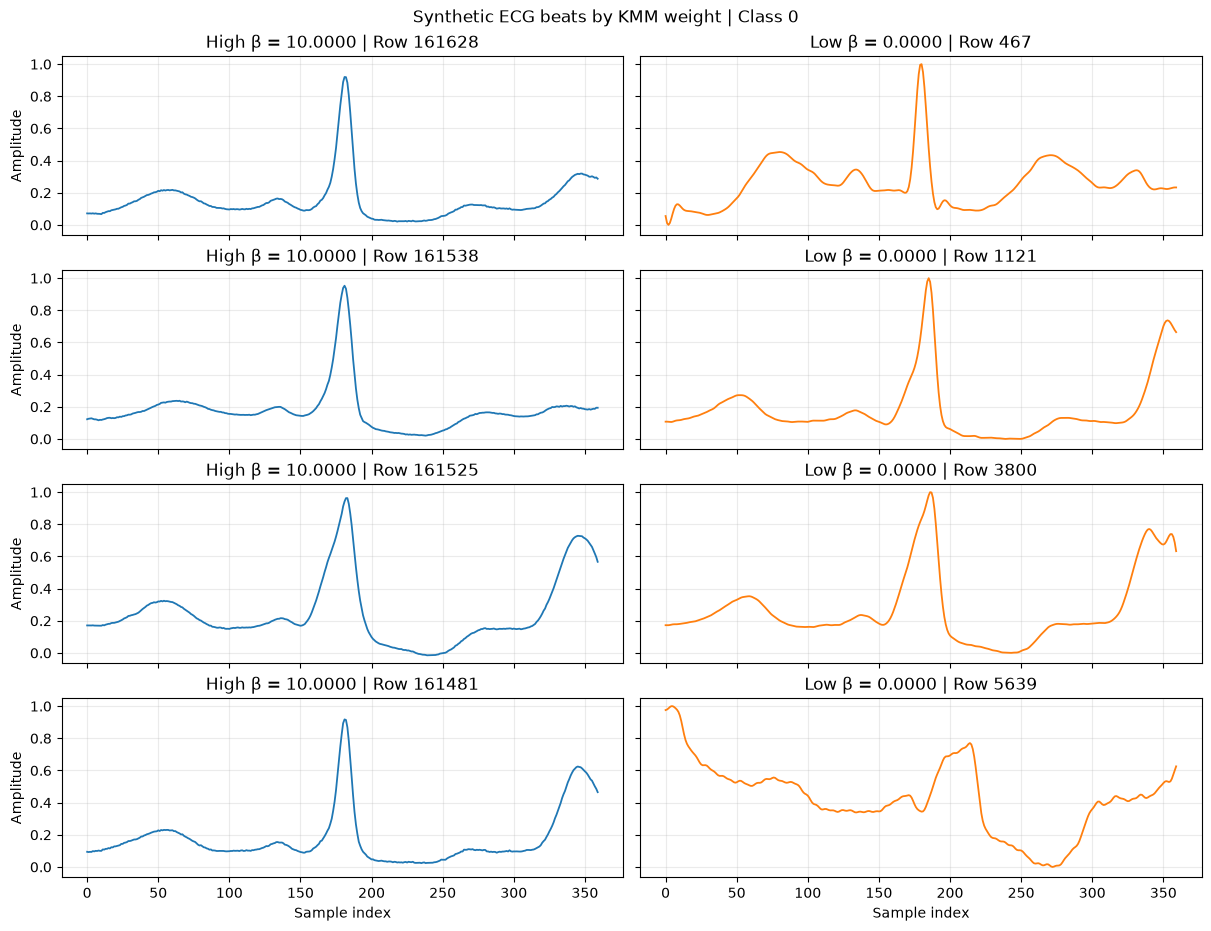

Saved figure: /workspace/ACS/Beta Code/kmm_output/high_vs_low_beta_class_0.png


In [15]:
CLASS_LABEL = 0
N_SHOW = 4

# Read the saved weights from the completed KMM run.
weights = np.load(OUTPUT_DIR / "beta_synthetic.npy").reshape(-1)
waves = X_syn_raw[:, :, 0]  # (beats, 360 samples)

if len(weights) != len(y_syn) or len(weights) != len(waves):
    raise ValueError("The beta file must match the synthetic ECG rows and labels.")

class_rows = np.flatnonzero(y_syn == CLASS_LABEL)
n = min(N_SHOW, len(class_rows) // 2)

if n == 0:
    raise ValueError(f"Class {CLASS_LABEL} needs at least two synthetic beats.")

if not np.isfinite(weights[class_rows]).all():
    raise ValueError(f"Class {CLASS_LABEL} contains non-finite beta values.")

# Rank within the selected class while keeping the original row indices.
ranked_rows = class_rows[np.argsort(weights[class_rows], kind="stable")]
high_rows = ranked_rows[-n:][::-1]
low_rows = ranked_rows[:n]

fig, axes = plt.subplots(
    n, 2, figsize=(12, 2.3 * n),
    sharex=True, sharey=True, squeeze=False,
    constrained_layout=True,
)

for i, (high_row, low_row) in enumerate(zip(high_rows, low_rows)):
    for col, row, label, color in [
        (0, high_row, "High β", "tab:blue"),
        (1, low_row, "Low β", "tab:orange"),
    ]:
        ax = axes[i, col]
        beat = waves[row]

        if np.isfinite(beat).sum() < 2:
            raise ValueError(f"Synthetic row {row} has fewer than two finite samples.")

        ax.plot(beat, color=color, linewidth=1.3)
        ax.set_title(f"{label} = {weights[row]:.4f} | Row {row}")
        ax.grid(alpha=0.25)

    axes[i, 0].set_ylabel("Amplitude")

for ax in axes[-1]:
    ax.set_xlabel("Sample index")

fig.suptitle(f"Synthetic ECG beats by KMM weight | Class {CLASS_LABEL}")

plot_path = OUTPUT_DIR / f"high_vs_low_beta_class_{CLASS_LABEL}.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved figure:", plot_path.resolve())

Available real labels: [0 1 2 3 4]
Available synthetic labels: [0 1 2 3 4]
F | high_beta | n=7,226 | β range 4.698–10.000
F | low_beta | n=7,226 | β range 0.000–0.000
S | high_beta | n=7,226 | β range 4.509–10.000
S | low_beta | n=7,226 | β range 0.000–0.000
V | high_beta | n=7,226 | β range 4.581–10.000
V | low_beta | n=7,226 | β range 0.000–0.000


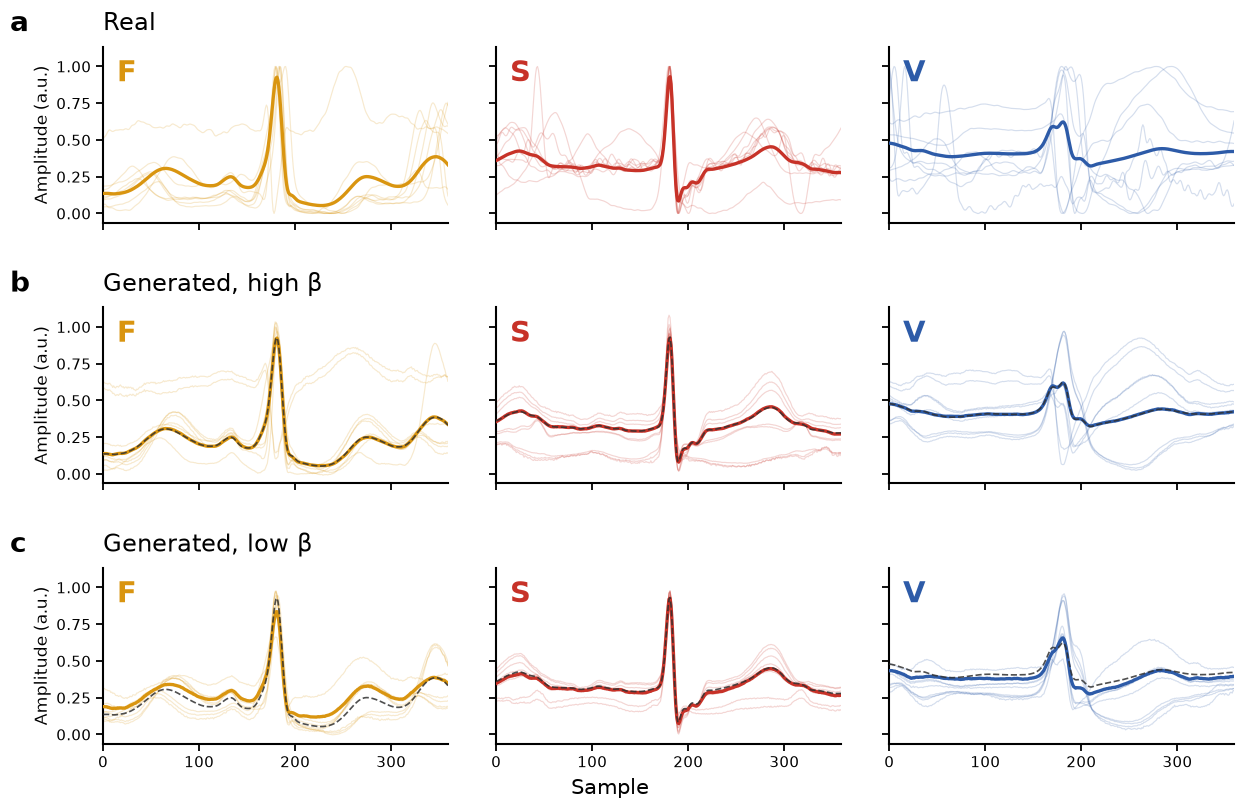

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Match these values to your dataset's label encoding.
CLASS_LABELS = {"F": 0, "S": 3, "V": 4}
COLORS = {"F": "#D99510", "S": "#C73228", "V": "#2D5BA8"}

TAIL_FRACTION = 0.10
N_OVERLAYS = 8
AMPLITUDE_LABEL = "Amplitude (a.u.)"  # Use mV if the saved data are in mV.
rng_plot = np.random.default_rng(42)

weights = np.load(OUTPUT_DIR / "beta_synthetic.npy").reshape(-1)


def single_lead(data):
    if data.ndim == 2:
        return data
    if data.ndim == 3 and data.shape[-1] == 1:
        return data[:, :, 0]
    if data.ndim == 3 and data.shape[1] == 1:
        return data[:, 0, :]
    raise ValueError(f"Expected a single-lead ECG array, got {data.shape}.")


def mean_waveform(waves, rows, block_size=2048):
    total = np.zeros(waves.shape[1], dtype=np.float64)
    for start in range(0, len(rows), block_size):
        block = waves[rows[start:start + block_size]]
        total += block.sum(axis=0, dtype=np.float64)
    return total / len(rows)


real = single_lead(X_real_raw)
syn = single_lead(X_syn_raw)

if len(real) != len(y_real) or len(syn) != len(y_syn) or len(syn) != len(weights):
    raise ValueError("ECG rows, labels, and saved beta values must match.")
if real.shape[1] != syn.shape[1]:
    raise ValueError("Real and synthetic beats must have the same sample length.")
if not np.isfinite(weights).all():
    raise ValueError("The saved beta file contains non-finite values.")

print("Available real labels:", np.unique(y_real))
print("Available synthetic labels:", np.unique(y_syn))

for name, label in CLASS_LABELS.items():
    if not np.any(y_real == label) or not np.any(y_syn == label):
        raise ValueError(f"Set CLASS_LABELS['{name}'] to its actual dataset label.")

fig, axes = plt.subplots(
    3, 3, figsize=(13, 8.5),
    sharex=True, sharey=True, facecolor="white",
)
fig.subplots_adjust(
    left=0.11, right=0.98, bottom=0.10, top=0.92,
    wspace=0.14, hspace=0.48,
)

samples = np.arange(real.shape[1])
row_titles = ["Real", "Generated, high β", "Generated, low β"]
plotted_rows = []

for col, (name, label) in enumerate(CLASS_LABELS.items()):
    color = COLORS[name]
    real_rows = np.flatnonzero(y_real == label)
    syn_rows = np.flatnonzero(y_syn == label)

    if len(syn_rows) < 2:
        raise ValueError(f"Class {name} needs at least two synthetic beats.")

    # Randomize tie order reproducibly before sorting by beta.
    shuffled = rng_plot.permutation(syn_rows)
    ranked = shuffled[np.argsort(weights[shuffled], kind="stable")]
    n_tail = max(1, int(TAIL_FRACTION * len(ranked)))
    low_rows = ranked[:n_tail]
    high_rows = ranked[-n_tail:]

    groups = [
        (real, real_rows, "real"),
        (syn, high_rows, "high_beta"),
        (syn, low_rows, "low_beta"),
    ]
    real_mean = mean_waveform(real, real_rows)

    for row, (waves, group_rows, group_name) in enumerate(groups):
        ax = axes[row, col]
        examples = rng_plot.choice(
            group_rows, size=min(N_OVERLAYS, len(group_rows)), replace=False
        )

        for idx in examples:
            ax.plot(samples, waves[idx], color=color, alpha=0.20, lw=0.85)
            plotted_rows.append({
                "class": name,
                "dataset_label": label,
                "group": group_name,
                "row_index": int(idx),
                "beta": "" if row == 0 else float(weights[idx]),
            })

        group_mean = real_mean if row == 0 else mean_waveform(waves, group_rows)
        ax.plot(samples, group_mean, color=color, lw=2.4, zorder=3)

        if row > 0:
            ax.plot(
                samples, real_mean, "--", color="#303030",
                lw=1.2, alpha=0.85, zorder=4,
            )
            print(
                f"{name} | {group_name} | n={len(group_rows):,} | "
                f"β range {weights[group_rows].min():.3f}–"
                f"{weights[group_rows].max():.3f}"
            )

        ax.text(
            0.04, 0.93, name, transform=ax.transAxes,
            color=color, fontsize=21, fontweight="bold", va="top",
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_linewidth(1.5)
        ax.tick_params(labelsize=11, width=1.3, length=5, labelleft=(col == 0))
        ax.set_xlim(samples[0], samples[-1])

for row, title in enumerate(row_titles):
    ax = axes[row, 0]
    ax.set_ylabel(AMPLITUDE_LABEL, fontsize=12)
    ax.text(
        -0.27, 1.13, "abc"[row], transform=ax.transAxes,
        fontsize=20, fontweight="bold", va="center",
    )
    ax.text(
        0, 1.13, title, transform=ax.transAxes,
        fontsize=17, va="center",
    )

fig.supxlabel("Sample", y=0.035, fontsize=15)

stem = OUTPUT_DIR / "real_vs_high_low_beta_FSV"
fig.savefig(stem.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.15)
fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.15)
pd.DataFrame(plotted_rows).to_csv(
    OUTPUT_DIR / "high_low_beta_plotted_rows.csv", index=False
)

plt.show()

In [17]:
for name, y in [("Real", y_real), ("Synthetic", y_syn)]:
    labels, counts = np.unique(y, return_counts=True)
    print(f"\n{name} labels:")
    for label, count in zip(labels, counts):
        print(f"  {label!r} → {count:,} beats")


Real labels:
  np.int64(0) → 642 beats
  np.int64(1) → 72,269 beats
  np.int64(2) → 9,111 beats
  np.int64(3) → 2,225 beats
  np.int64(4) → 5,788 beats

Synthetic labels:
  np.int64(0) → 72,269 beats
  np.int64(1) → 72,269 beats
  np.int64(2) → 72,269 beats
  np.int64(3) → 72,269 beats
  np.int64(4) → 72,269 beats


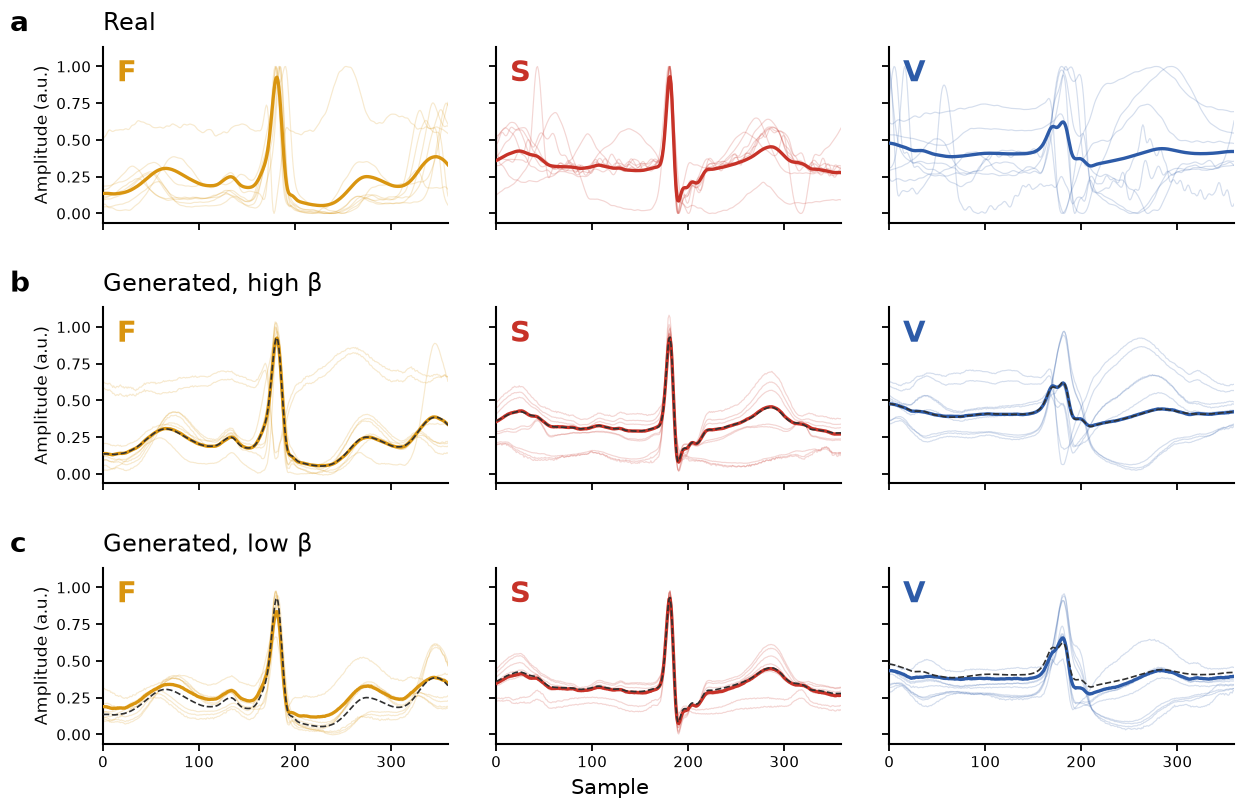

Class  Group  Beats  Beta min  Beta median  Beta max  Mean waveform RMSE
    F High β   7226   4.69750         10.0      10.0             0.00293
    F  Low β   7226   0.00000          0.0       0.0             0.05309
    S High β   7226   4.50877         10.0      10.0             0.00325
    S  Low β   7226   0.00000          0.0       0.0             0.01026
    V High β   7226   4.58051         10.0      10.0             0.00256
    V  Low β   7226   0.00000          0.0       0.0             0.03133

Saved figures and CSV files in /workspace/ACS/Beta Code/kmm_output


In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Use your verified dataset mapping. Add quotes if the IDs are stored as text.
CLASS_LABELS = {"F": 0, "S": 3, "V": 4}
COLORS = {"F": "#D99510", "S": "#C73228", "V": "#2D5BA8"}

TAIL_FRACTION = 0.10
N_OVERLAYS = 8
AMPLITUDE_LABEL = "Amplitude (a.u.)"  # Use mV if your saved amplitudes are in mV.
rng_plot = np.random.default_rng(42)

weights = np.load(OUTPUT_DIR / "beta_synthetic.npy").reshape(-1)


def single_lead(data):
    if data.ndim == 2:
        return data
    if data.ndim == 3 and data.shape[-1] == 1:
        return data[:, :, 0]  # Your synthetic shape: (beats, 360, 1)
    if data.ndim == 3 and data.shape[1] == 1:
        return data[:, 0, :]
    raise ValueError(f"Expected single-lead ECG data, got {data.shape}.")


def mean_waveform(waves, rows, block_size=2048):
    total = np.zeros(waves.shape[1], dtype=np.float64)

    for start in range(0, len(rows), block_size):
        block = waves[rows[start:start + block_size]]
        total += block.sum(axis=0, dtype=np.float64)

    return total / len(rows)


real = single_lead(X_real_raw)
syn = single_lead(X_syn_raw)

if len(real) != len(y_real) or len(syn) != len(y_syn) or len(syn) != len(weights):
    raise ValueError("ECG rows, labels, and saved beta values must match.")
if real.shape[1] != syn.shape[1]:
    raise ValueError("Real and synthetic beats must have the same sample length.")
if not np.isfinite(weights).all():
    raise ValueError("The saved beta file contains non-finite values.")
if not 0 < TAIL_FRACTION <= 0.5:
    raise ValueError("TAIL_FRACTION must be greater than 0 and at most 0.5.")

for name, label in CLASS_LABELS.items():
    if not np.any(y_real == label) or not np.any(y_syn == label):
        raise ValueError(
            f"Check the mapping for {name}: label {label!r} "
            "must appear in both datasets."
        )

fig, axes = plt.subplots(
    3, 3, figsize=(13, 8.5), sharex=True, sharey=True, facecolor="white"
)
fig.subplots_adjust(
    left=0.11, right=0.98, bottom=0.10, top=0.92,
    wspace=0.14, hspace=0.48
)

samples = np.arange(real.shape[1])
row_titles = ["Real", "Generated, high β", "Generated, low β"]
plotted_rows = []
summary_rows = []

for col, (name, label) in enumerate(CLASS_LABELS.items()):
    color = COLORS[name]
    real_rows = np.flatnonzero(y_real == label)
    syn_rows = np.flatnonzero(y_syn == label)

    if len(syn_rows) < 2:
        raise ValueError(f"Class {name} needs at least two synthetic beats.")

    # Randomize ties with a fixed seed, then rank within the class.
    shuffled = rng_plot.permutation(syn_rows)
    ranked = shuffled[np.argsort(weights[shuffled], kind="stable")]
    n_tail = max(1, int(TAIL_FRACTION * len(ranked)))
    high_rows = ranked[-n_tail:]
    low_rows = ranked[:n_tail]

    real_mean = mean_waveform(real, real_rows)

    if weights[low_rows].max() >= weights[high_rows].min():
        print(f"Class {name}: the low-β and high-β groups share a boundary value.")

    groups = [
        (real, real_rows, "Real"),
        (syn, high_rows, "High β"),
        (syn, low_rows, "Low β"),
    ]

    for row, (waves, ids, group_name) in enumerate(groups):
        ax = axes[row, col]
        group_mean = real_mean if row == 0 else mean_waveform(waves, ids)

        if not np.isfinite(group_mean).all():
            raise ValueError(f"Class {name}, {group_name}: non-finite waveform values.")

        examples = rng_plot.choice(
            ids, size=min(N_OVERLAYS, len(ids)), replace=False
        )

        for idx in examples:
            ax.plot(samples, waves[idx], color=color, alpha=0.20, lw=0.85)
            plotted_rows.append({
                "class": name,
                "dataset_label": label,
                "group": group_name,
                "row_index": int(idx),
                "beta": "" if row == 0 else float(weights[idx]),
            })

        ax.plot(samples, group_mean, color=color, lw=2.4, zorder=3)

        if row > 0:
            ax.plot(samples, real_mean, "--", color="#303030", lw=1.2, zorder=4)

            w = weights[ids]
            rmse = np.sqrt(np.mean((group_mean - real_mean) ** 2))
            summary_rows.append({
                "Class": name,
                "Group": group_name,
                "Beats": len(ids),
                "Beta min": w.min(),
                "Beta median": np.median(w),
                "Beta max": w.max(),
                "Mean waveform RMSE": rmse,
            })

        ax.text(
            0.04, 0.93, name, transform=ax.transAxes, color=color,
            fontsize=21, fontweight="bold", va="top"
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_linewidth(1.5)
        ax.tick_params(labelsize=11, width=1.3, length=5, labelleft=(col == 0))
        ax.set_xlim(samples[0], samples[-1])

for row, title in enumerate(row_titles):
    ax = axes[row, 0]
    ax.set_ylabel(AMPLITUDE_LABEL, fontsize=12)
    ax.text(
        -0.27, 1.13, "abc"[row], transform=ax.transAxes,
        fontsize=20, fontweight="bold", va="center"
    )
    ax.text(0, 1.13, title, transform=ax.transAxes, fontsize=17, va="center")

fig.supxlabel("Sample", y=0.035, fontsize=15)

stem = OUTPUT_DIR / "real_vs_high_low_beta_FSV"
fig.savefig(stem.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.15)
fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.15)

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUTPUT_DIR / "high_low_beta_summary.csv", index=False)
pd.DataFrame(plotted_rows).to_csv(
    OUTPUT_DIR / "high_low_beta_plotted_rows.csv", index=False
)

plt.show()
print(summary.round(5).to_string(index=False))
print("\nSaved figures and CSV files in", OUTPUT_DIR.resolve())

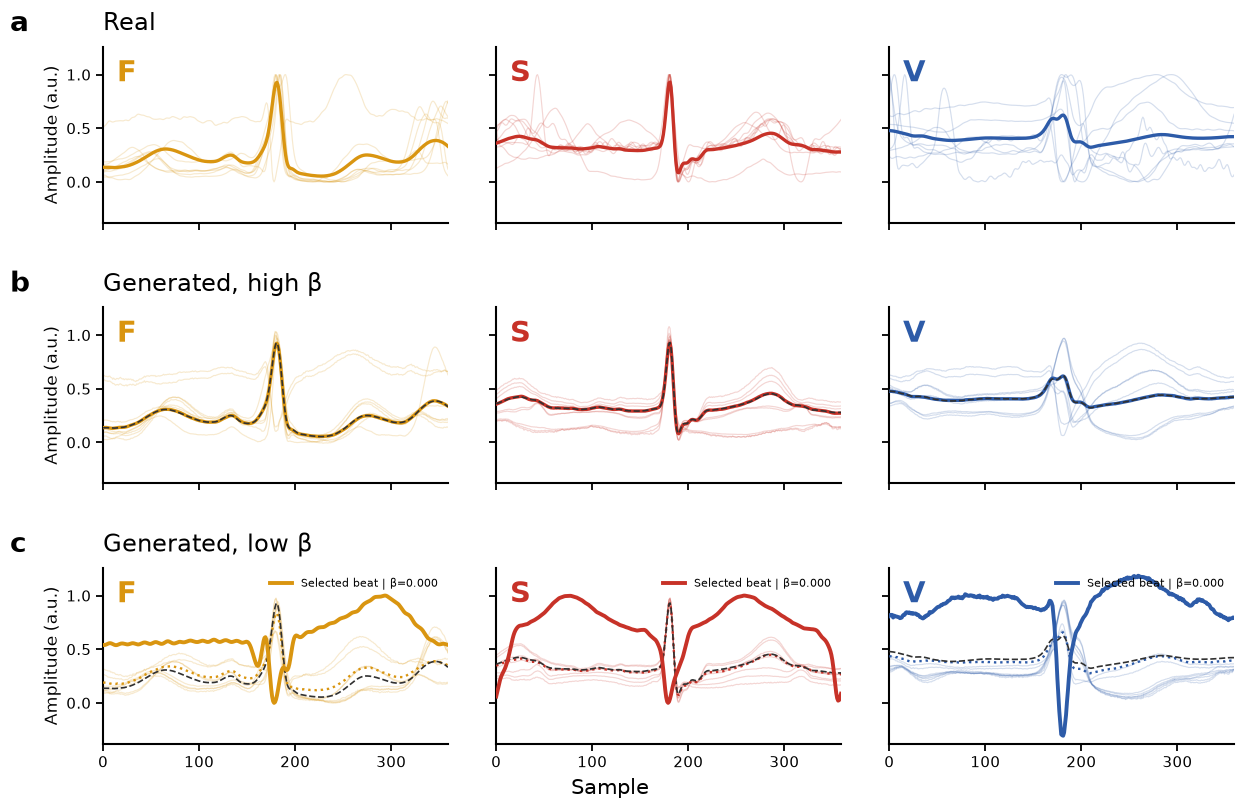

class  group  beats  beta_min  beta_median  beta_max  group_mean_rmse_to_real_mean  highlighted_row  highlighted_beat_rmse_to_real_mean
    F High β   7226   4.69750         10.0      10.0                       0.00293              NaN                                 NaN
    F  Low β   7226   0.00000          0.0       0.0                       0.05309          69302.0                             0.48766
    S High β   7226   4.50877         10.0      10.0                       0.00325              NaN                                 NaN
    S  Low β   7226   0.00000          0.0       0.0                       0.01026          40884.0                             0.46452
    V High β   7226   4.58051         10.0      10.0                       0.00256              NaN                                 NaN
    V  Low β   7226   0.00000          0.0       0.0                       0.03133         303112.0                             0.55544

Saved figures and CSVs in /workspace/ACS/Beta C

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Use quotes around the IDs if y_real and y_syn store text labels.
CLASS_LABELS = {"F": 0, "S": 3, "V": 4}
COLORS = {"F": "#D99510", "S": "#C73228", "V": "#2D5BA8"}

TAIL_FRACTION = 0.10
N_OVERLAYS = 8
BLOCK_SIZE = 2048
AMPLITUDE_LABEL = "Amplitude (a.u.)"  # Use mV if your data are in mV.
rng = np.random.default_rng(42)

weights = np.load(OUTPUT_DIR / "beta_synthetic.npy").reshape(-1)


def single_lead(data):
    if data.ndim == 2:
        return data
    if data.ndim == 3 and data.shape[-1] == 1:
        return data[:, :, 0]  # Your synthetic array: (beats, 360, 1)
    if data.ndim == 3 and data.shape[1] == 1:
        return data[:, 0, :]
    raise ValueError(f"Expected single-lead ECG data, got {data.shape}.")


def mean_waveform(waves, rows):
    total = np.zeros(waves.shape[1], dtype=np.float64)
    for start in range(0, len(rows), BLOCK_SIZE):
        block = waves[rows[start:start + BLOCK_SIZE]]
        total += block.sum(axis=0, dtype=np.float64)
    return total / len(rows)


def most_dissimilar_beat(waves, rows, reference):
    best_row, best_rmse = None, -np.inf

    for start in range(0, len(rows), BLOCK_SIZE):
        block_rows = rows[start:start + BLOCK_SIZE]
        difference = waves[block_rows] - reference
        rmse = np.sqrt(np.mean(difference ** 2, axis=1))
        i = int(np.argmax(rmse))

        if rmse[i] > best_rmse:
            best_row = int(block_rows[i])
            best_rmse = float(rmse[i])

    return best_row, best_rmse


real = single_lead(X_real_raw)
syn = single_lead(X_syn_raw)

if len(real) != len(y_real) or len(syn) != len(y_syn) or len(syn) != len(weights):
    raise ValueError("Waveform rows, labels, and saved beta values must match.")
if real.shape[1] != syn.shape[1] or syn.shape[1] < 2:
    raise ValueError("Real and synthetic beats need the same sample length.")
if not np.isfinite(weights).all():
    raise ValueError("The saved beta file contains non-finite values.")
if not 0 < TAIL_FRACTION <= 0.5:
    raise ValueError("TAIL_FRACTION must be greater than 0 and at most 0.5.")

fig, axes = plt.subplots(
    3, 3, figsize=(13, 8.5), sharex=True, sharey=True, facecolor="white"
)
fig.subplots_adjust(
    left=0.11, right=0.98, bottom=0.10, top=0.92,
    wspace=0.14, hspace=0.48,
)

samples = np.arange(real.shape[1])
row_titles = ["Real", "Generated, high β", "Generated, low β"]
plotted_rows = []
summary_rows = []

for col, (name, label) in enumerate(CLASS_LABELS.items()):
    color = COLORS[name]
    real_rows = np.flatnonzero(y_real == label)
    syn_rows = np.flatnonzero(y_syn == label)

    if len(real_rows) == 0 or len(syn_rows) < 2:
        raise ValueError(
            f"Check CLASS_LABELS['{name}'] = {label!r}. "
            "This class needs real beats and at least two synthetic beats."
        )

    # Randomize the order of equal weights reproducibly before ranking.
    shuffled = rng.permutation(syn_rows)
    ranked = shuffled[np.argsort(weights[shuffled], kind="stable")]
    n_tail = max(1, int(TAIL_FRACTION * len(ranked)))
    low_rows = ranked[:n_tail]
    high_rows = ranked[-n_tail:]

    if weights[low_rows].max() >= weights[high_rows].min():
        print(f"{name}: high- and low-β groups share a boundary value.")

    real_mean = mean_waveform(real, real_rows)
    groups = [
        (real, real_rows, "Real"),
        (syn, high_rows, "High β"),
        (syn, low_rows, "Low β"),
    ]

    for row, (waves, ids, group_name) in enumerate(groups):
        ax = axes[row, col]
        group_mean = real_mean if row == 0 else mean_waveform(waves, ids)

        if not np.isfinite(group_mean).all():
            raise ValueError(f"{name}, {group_name}: non-finite waveform values.")

        example_pool = ids
        if row == 2:
            selected_row, selected_rmse = most_dissimilar_beat(
                syn, low_rows, real_mean
            )
            # Avoid drawing the highlighted beat twice.
            example_pool = ids[ids != selected_row]

        examples = rng.choice(
            example_pool, size=min(N_OVERLAYS, len(example_pool)), replace=False
        )

        for idx in examples:
            ax.plot(samples, waves[idx], color=color, alpha=0.20, lw=0.85)
            plotted_rows.append({
                "class": name,
                "dataset_label": label,
                "group": group_name,
                "row_index": int(idx),
                "beta": None if row == 0 else float(weights[idx]),
            })

        ax.plot(
            samples, group_mean, color=color,
            linestyle=":" if row == 2 else "-",
            lw=1.7 if row == 2 else 2.4, zorder=3,
        )

        if row > 0:
            ax.plot(
                samples, real_mean, "--",
                color="#303030", lw=1.2, zorder=4,
            )
            w = weights[ids]
            summary_rows.append({
                "class": name,
                "group": group_name,
                "beats": len(ids),
                "beta_min": w.min(),
                "beta_median": np.median(w),
                "beta_max": w.max(),
                "group_mean_rmse_to_real_mean": np.sqrt(
                    np.mean((group_mean - real_mean) ** 2)
                ),
                "highlighted_row": selected_row if row == 2 else None,
                "highlighted_beat_rmse_to_real_mean": (
                    selected_rmse if row == 2 else None
                ),
            })

        if row == 2:
            ax.plot(
                samples, syn[selected_row], color=color, lw=2.8, zorder=5,
                label=f"Selected beat | β={weights[selected_row]:.3f}",
            )
            ax.legend(loc="upper right", fontsize=8, frameon=False)
            plotted_rows.append({
                "class": name,
                "dataset_label": label,
                "group": "Low β, largest RMSE example",
                "row_index": selected_row,
                "beta": float(weights[selected_row]),
                "waveform_rmse_to_real_mean": selected_rmse,
            })

        ax.text(
            0.04, 0.93, name, transform=ax.transAxes,
            color=color, fontsize=21, fontweight="bold", va="top",
        )
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_linewidth(1.5)
        ax.tick_params(labelsize=11, width=1.3, length=5, labelleft=(col == 0))
        ax.set_xlim(samples[0], samples[-1])

for row, title in enumerate(row_titles):
    ax = axes[row, 0]
    ax.set_ylabel(AMPLITUDE_LABEL, fontsize=12)
    ax.text(
        -0.27, 1.13, "abc"[row], transform=ax.transAxes,
        fontsize=20, fontweight="bold", va="center",
    )
    ax.text(0, 1.13, title, transform=ax.transAxes, fontsize=17, va="center")

fig.supxlabel("Sample", y=0.035, fontsize=15)

stem = OUTPUT_DIR / "real_vs_high_low_beta_FSV_highlighted"
fig.savefig(stem.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.15)
fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.15)

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUTPUT_DIR / "high_low_beta_highlighted_summary.csv", index=False)
pd.DataFrame(plotted_rows).to_csv(
    OUTPUT_DIR / "high_low_beta_highlighted_rows.csv", index=False
)

plt.show()
print(summary.round(5).to_string(index=False))
print("\nSaved figures and CSVs in", OUTPUT_DIR.resolve())

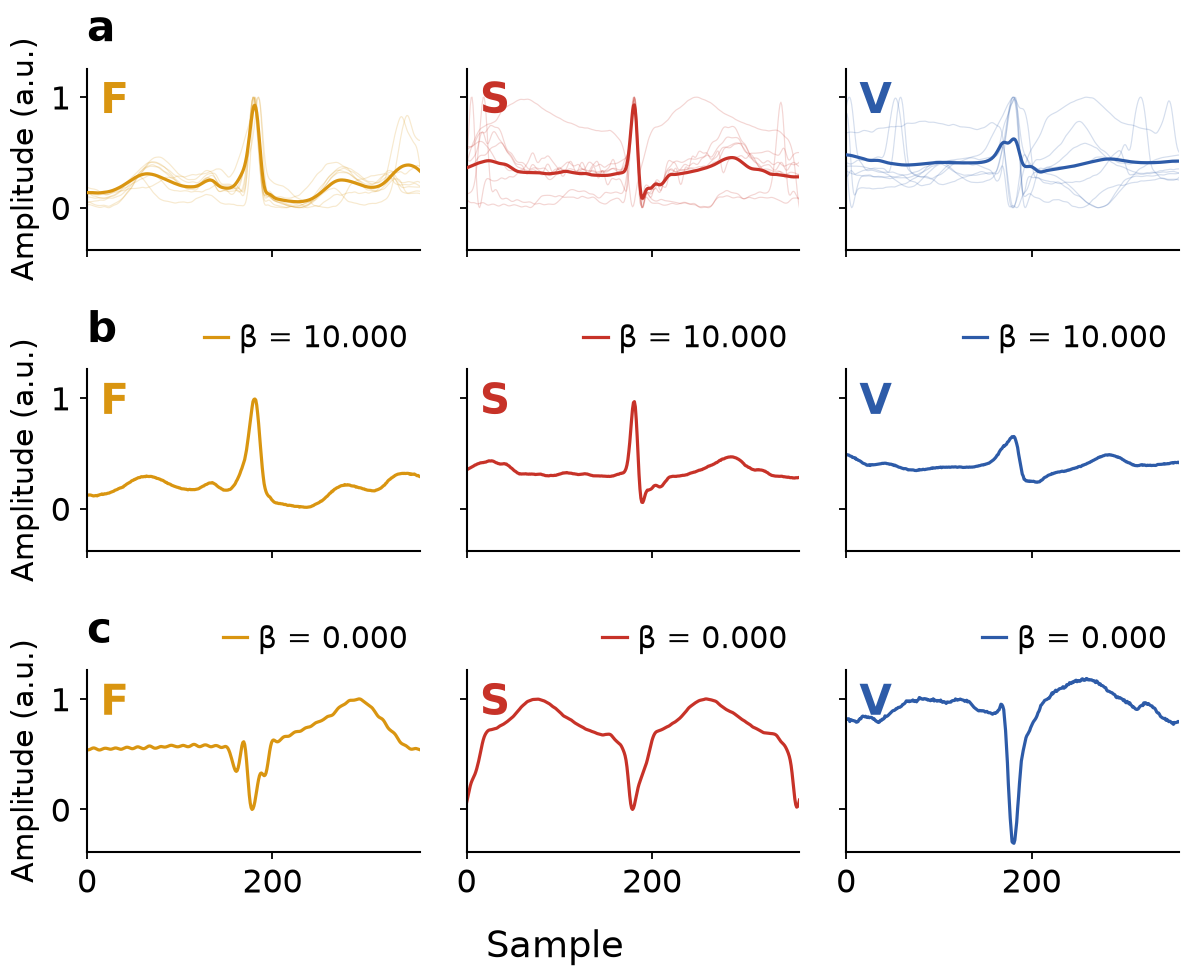

Saved figure: /workspace/ACS/Beta Code/kmm_output/FSV_single_column_readable.pdf


In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CLASS_LABELS = {"F": 0, "S": 3, "V": 4}
COLORS = {"F": "#D99510", "S": "#C73228", "V": "#2D5BA8"}

TAIL_FRACTION = 0.10
N_REAL_OVERLAYS = 8
BLOCK_SIZE = 2048
AMPLITUDE_LABEL = "Amplitude (a.u.)"

# Figure size and printed font sizes
ORIGINAL_WIDTH = 13
ORIGINAL_HEIGHT = 8.5
HEIGHT_INCREASE = 1.10
COLUMN_WIDTH_IN = 3.45

font_scale = ORIGINAL_WIDTH / COLUMN_WIDTH_IN

rng = np.random.default_rng(42)
weights = np.load(OUTPUT_DIR / "beta_synthetic.npy").reshape(-1)


def single_lead(data):
    if data.ndim == 2:
        return data
    if data.ndim == 3 and data.shape[-1] == 1:
        return data[:, :, 0]
    if data.ndim == 3 and data.shape[1] == 1:
        return data[:, 0, :]
    raise ValueError(f"Expected single-lead ECG data, got {data.shape}.")


def mean_waveform(waves, rows):
    total = np.zeros(waves.shape[1], dtype=np.float64)

    for start in range(0, len(rows), BLOCK_SIZE):
        block = waves[rows[start:start + BLOCK_SIZE]]
        total += block.sum(axis=0, dtype=np.float64)

    return total / len(rows)


def select_beat(waves, rows, reference, farthest=False):
    best_row = None
    best_mse = -np.inf if farthest else np.inf
    choose_index = np.argmax if farthest else np.argmin

    for start in range(0, len(rows), BLOCK_SIZE):
        block_rows = rows[start:start + BLOCK_SIZE]
        difference = waves[block_rows] - reference
        mse = np.mean(difference ** 2, axis=1)
        i = int(choose_index(mse))
        score = float(mse[i])

        improved = score > best_mse if farthest else score < best_mse
        if improved:
            best_row = int(block_rows[i])
            best_mse = score

    return best_row


real = single_lead(X_real_raw)
syn = single_lead(X_syn_raw)

if len(real) != len(y_real) or len(syn) != len(y_syn) or len(syn) != len(weights):
    raise ValueError("Waveform rows, labels, and saved beta values must match.")
if real.shape[1] != syn.shape[1] or syn.shape[1] < 2:
    raise ValueError("Real and synthetic beats need the same sample length.")
if not np.isfinite(weights).all():
    raise ValueError("The saved beta file contains non-finite values.")
if not 0 < TAIL_FRACTION <= 0.5:
    raise ValueError("TAIL_FRACTION must be greater than 0 and at most 0.5.")

fig, axes = plt.subplots(
    3, 3,
    figsize=(ORIGINAL_WIDTH, ORIGINAL_HEIGHT * HEIGHT_INCREASE),
    sharex=True,
    sharey=True,
    facecolor="white",
)

fig.subplots_adjust(
    left=0.11, right=0.98,
    bottom=0.10, top=0.92,
    wspace=0.14, hspace=0.42,
)

samples = np.arange(real.shape[1])
row_titles = ["Real", "Generated, high β", "Generated, low β"]
plotted_rows = []
summary_rows = []

for col, (name, label) in enumerate(CLASS_LABELS.items()):
    color = COLORS[name]
    real_rows = np.flatnonzero(y_real == label)
    syn_rows = np.flatnonzero(y_syn == label)

    if len(real_rows) == 0 or len(syn_rows) < 2:
        raise ValueError(f"Check the label mapping for class {name}: {label!r}.")

    shuffled = rng.permutation(syn_rows)
    ranked = shuffled[np.argsort(weights[shuffled], kind="stable")]
    n_tail = max(1, int(TAIL_FRACTION * len(ranked)))
    high_rows = ranked[-n_tail:]
    low_rows = ranked[:n_tail]

    real_mean = mean_waveform(real, real_rows)
    high_mean = mean_waveform(syn, high_rows)
    low_mean = mean_waveform(syn, low_rows)

    if not all(np.isfinite(mean).all() for mean in (real_mean, high_mean, low_mean)):
        raise ValueError(f"Class {name} contains non-finite waveform values.")

    high_idx = select_beat(syn, high_rows, high_mean)
    low_idx = select_beat(syn, low_rows, real_mean, farthest=True)

    # Real row: faint individual ECGs with the class mean on top.
    ax_real = axes[0, col]
    rng_real = np.random.default_rng(100 + col)
    examples = rng_real.choice(
        real_rows, size=min(N_REAL_OVERLAYS, len(real_rows)), replace=False
    )

    for idx in examples:
        ax_real.plot(samples, real[idx], color=color, alpha=0.20, lw=0.85)

    ax_real.plot(samples, real_mean, color=color, lw=2.3, zorder=3)

    panels = [
        (1, "High β", high_idx, high_rows, high_mean, "Closest to high-β mean"),
        (2, "Low β", low_idx, low_rows, low_mean, "Farthest from real mean"),
    ]

    for row, group, idx, ids, group_mean, selection in panels:
        ax = axes[row, col]
        ax.plot(
            samples, syn[idx],
            color=color, lw=2.3,
            label=f"β = {weights[idx]:.3f}",
        )
        ax.legend(
            loc="upper right",
            fontsize=7 * font_scale,
            frameon=False,
            handlelength=0.8,
            handletextpad=0.4,
        )

        beat_rmse = np.sqrt(np.mean((syn[idx] - real_mean) ** 2))
        group_rmse = np.sqrt(np.mean((group_mean - real_mean) ** 2))

        plotted_rows.append({
            "class": name,
            "dataset_label": label,
            "group": group,
            "row_index": idx,
            "beta": float(weights[idx]),
            "selection_rule": selection,
            "beat_rmse_to_real_mean": beat_rmse,
        })

        summary_rows.append({
            "class": name,
            "group": group,
            "beats": len(ids),
            "beta_min": weights[ids].min(),
            "beta_median": np.median(weights[ids]),
            "beta_max": weights[ids].max(),
            "group_mean_rmse_to_real_mean": group_rmse,
            "selected_row": idx,
            "selected_beat_rmse_to_real_mean": beat_rmse,
        })

    for ax in axes[:, col]:
        ax.text(
            0.04, 0.93, name,
            transform=ax.transAxes,
            color=color,
            fontsize=9 * font_scale,
            fontweight="bold",
            va="top",
        )
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_linewidth(1.5)

        ax.tick_params(
            labelsize=7 * font_scale, width=1.3, length=5,
            labelleft=(col == 0),
        )
        ax.set_xlim(samples[0], samples[-1])

for row, title in enumerate(row_titles):
    ax = axes[row, 0]
    ax.set_ylabel(AMPLITUDE_LABEL, fontsize=7.5 * font_scale)

    ax.text(
        -0.27, 1.12, "abc"[row],
        transform=ax.transAxes,
        fontsize=9 * font_scale,
        fontweight="bold",
        va="center",
    )
    ax.text(
        0, 1.12, title,
        transform=ax.transAxes,
        fontsize=8 * font_scale,
        va="center",
    )

# Final formatting for the original 3 × 3 figure.
fig.set_size_inches(13, 10.8)
fig.subplots_adjust(
    left=0.14, right=0.98,
    bottom=0.14, top=0.865,
    wspace=0.14, hspace=0.66,
)

scale = 13 / COLUMN_WIDTH_IN
old_headers = {
    "Real", "Generated, high β", "Generated, low β",
    "a", "b", "c",
}

for row in range(3):
    for col in range(3):
        ax = axes[row, col]
        ax.tick_params(axis="both", labelsize=6.2 * scale, pad=1.8 * scale)
        ax.yaxis.label.set_fontsize(5.7 * scale)
        ax.yaxis.labelpad = 2 * scale

        # Delete the old row titles and panel letters.
        for text in list(ax.texts):
            if text.get_text() in old_headers:
                text.remove()
            elif text.get_text() in {"F", "S", "V"}:
                text.set_fontsize(8 * scale)

        if row > 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.legend(
                handles, labels,
                loc="lower right",
                bbox_to_anchor=(1.0, 1.015),
                fontsize=5.8 * scale,
                frameon=False,
                handlelength=0.8,
                handletextpad=0.35,
                borderaxespad=0,
            )

    # Add only the panel letter, aligned above the first plot.
    box = axes[row, 0].get_position()
    fig.text(
        box.x0, box.y1 + 0.016, "abc"[row],
        fontsize=8 * scale,
        fontweight="bold",
        ha="left",
        va="bottom",
    )

fig.supxlabel("Sample", y=0.034, fontsize=7 * scale)

stem = OUTPUT_DIR / "FSV_single_column_readable"
fig.savefig(stem.with_suffix(".pdf"), facecolor="white")
fig.savefig(stem.with_suffix(".png"), dpi=600, facecolor="white")

pd.DataFrame(plotted_rows).to_csv(
    OUTPUT_DIR / "high_low_beta_single_beat_rows.csv", index=False
)
pd.DataFrame(summary_rows).to_csv(
    OUTPUT_DIR / "high_low_beta_single_beat_summary.csv", index=False
)

plt.show()
print("Saved figure:", stem.with_suffix(".pdf").resolve())